# 07 — Integração: imagem + pergunta → visão + PLN + regras (Exp 5)

Todos os resultados vêm do modelo real; não há probabilidades digitadas.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
from src.agents import CoordinatorAgent
co = CoordinatorAgent(); EX = ROOT / 'results' / 'exemplos'
for img, msg in [('plantvillage_Tomato_Late_blight.jpg', 'Folhas encharcadas escuras com mofo branco embaixo. Como tratar?'),
                 ('plantvillage_Tomato_healthy.jpg', 'Pústulas marrom-avermelhadas cor de ferrugem nas folhas de milho. Qual doença é essa?'),
                 ('plantdoc_Potato_Late_blight.jpg', 'Como evitar isso?')]:
    r = co.answer(EX / img, msg)
    print(img, '|', msg); print('  intenção:', r.intent, '| status:', r.decision.status.value, '| classe:', r.decision.final_class); print('  ', r.answer[:240], '\n')

plantvillage_Tomato_Late_blight.jpg | Folhas encharcadas escuras com mofo branco embaixo. Como tratar?
  intenção: treatment | status: CONFIRMADO_POR_MULTIPLAS_EVIDENCIAS | classe: Tomato___Late_blight
   Diagnóstico mais provável: Requeima (Mela) (Tomate (Solanum lycopersicum)), confiança 85% [CONFIRMADO_POR_MULTIPLAS_EVIDENCIAS]. Doença de rápida progressão em condições frias e úmidas. Isolar focos iniciais, reduzir molhamento foliar prolo 

plantvillage_Tomato_healthy.jpg | Pústulas marrom-avermelhadas cor de ferrugem nas folhas de milho. Qual doença é essa?
  intenção: diagnose | status: DIVERGENCIA_DETECTADA | classe: None
   Não há evidência suficiente para responder com segurança. DIVERGÊNCIA DETECTADA: Os modelos de Visão Computacional e PLN apontam para diagnósticos conflitantes. Por rigor científico, o sistema NÃO oculta essa contradição e não emite um laud 

plantdoc_Potato_Late_blight.jpg | Como evitar isso?
  intenção: prevention | status: DIAGNOSTICO_SOMENTE_VISUAL | clas

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [3]:
e5 = json.load(open(M/'exp5_multiagent_ablation.json'))
rows=[]
for ds_name in ('plantvillage_test','plantdoc_field'):
    for mode in ('vision_only','nlp_only','integrated'):
        r = e5[ds_name]['headline_p0'][mode]; rows.append({'conjunto':ds_name,'modo':mode, **{k:r[k] for k in ('accuracy','coverage','accuracy_when_answered','f1_macro')}})
display(pd.DataFrame(rows))

,conjunto,modo,accuracy,coverage,accuracy_when_answered,f1_macro
0,plantvillage_test,vision_only,0.9526,0.9644,0.9877,0.9692
1,plantvillage_test,nlp_only,0.7630,0.8760,0.8710,0.8088
2,plantvillage_test,integrated,0.8769,0.8833,0.9928,0.9251
3,plantdoc_field,vision_only,0.3993,0.8379,0.4766,0.3548
4,plantdoc_field,nlp_only,0.7765,0.8976,0.8650,0.8201
5,plantdoc_field,integrated,0.4249,0.4846,0.8768,0.4797


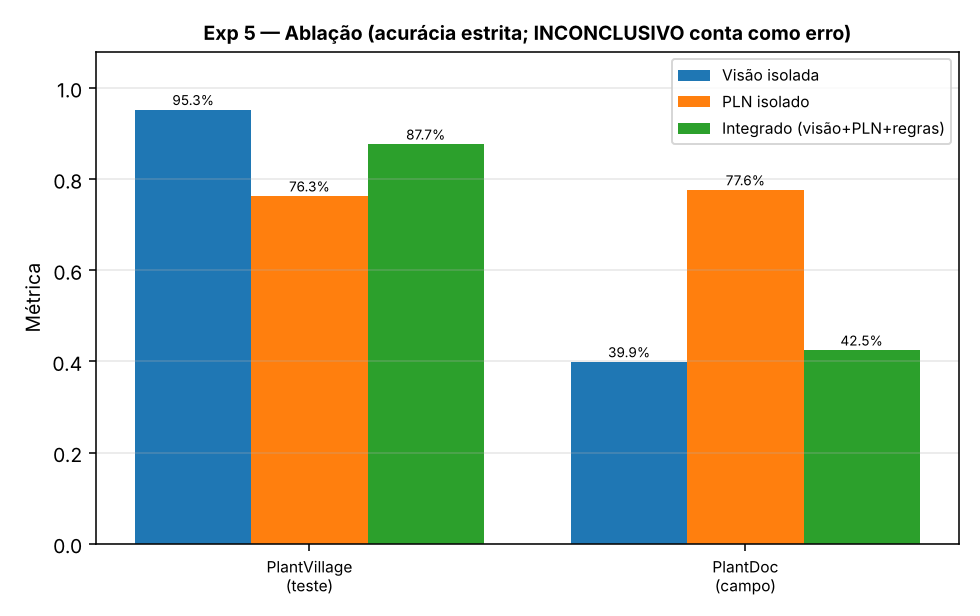

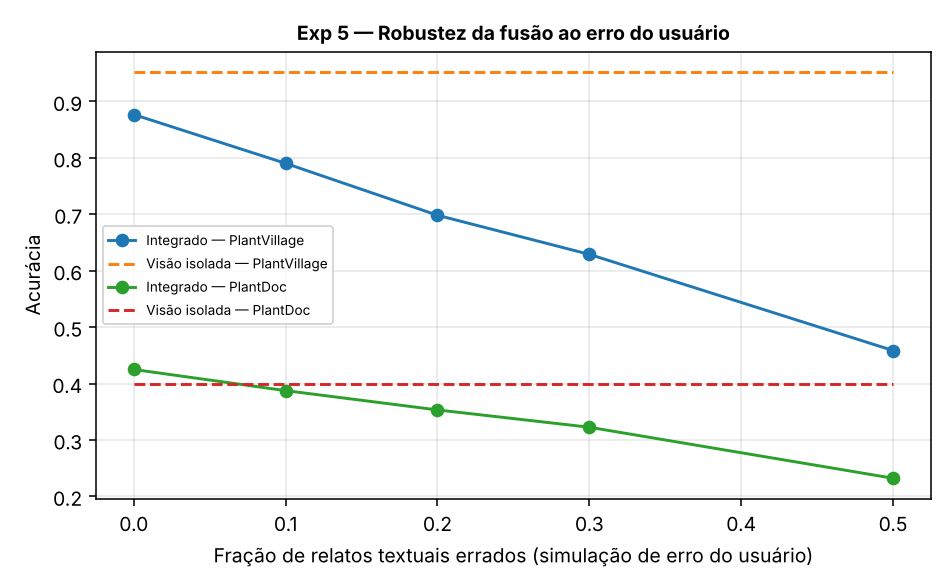

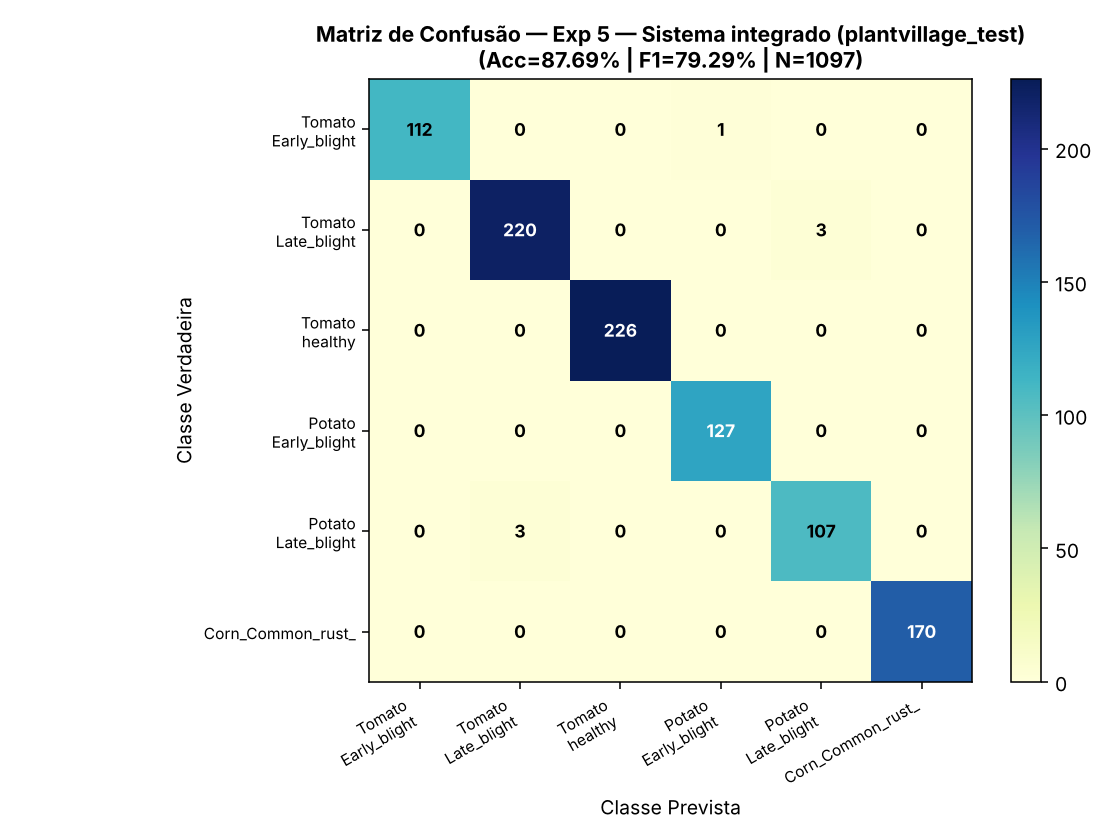

In [4]:
show('plots/exp5_multiagent_ablation.png'); show('plots/exp5_sensitivity.png'); show('confusion_matrices/exp5_multiagent_integrated_cm.png')

**Leitura honesta:** a acurácia *estrita* do integrado é menor que a da visão em PlantVillage porque divergências viram `INCONCLUSIVO` (o sistema se abstém). A vantagem é a **precisão quando responde** e a detecção de erro (principalmente em campo). Ver Docs/experiments.md.